# Aligning the A-scans of an ultrasonic (PAUT) scan to the entrance echo

**What this notebook does, in one sentence:** it makes the front surface of the part *flat* in your
ultrasonic data, by moving every A-scan up or down so that the echo of the front surface (the
*entrance echo*) is at depth 0 in all of them.

**Why you want this.** During a scan, the distance between the probe and the part is never exactly the same
everywhere: the part may be tilted, warped, curved, or the scanner may wobble. In the raw data this shows
up as a front surface that is inclined or bent in the B-scans, and every reflection inside the part
(defects, plies, the back wall) is bent with it. After the alignment:

* the front surface is a straight line at 0 mm in every B-scan,
* the depth of anything you see is directly its **depth below the surface**,
* C-scans (maps at a given depth) really show one depth below the surface, instead of cutting
  diagonally through the part.

**The A-scans are moved by fractions of a sample, using the FFT.** The echo rarely falls exactly on a
sample, so the A-scans are moved by non-whole amounts (e.g. 37.4 samples). This is done in the frequency
domain (FFT), which moves the signal without smoothing it or changing its values; section 7 explains it and
compares it with simple interpolation.

**It works for any shape, not only for a tilt.** Every A-scan gets its own correction, so a part that looks
curved, wavy or bowl-shaped in the raw data is flattened exactly like a tilted one. Section 8 looks at this
in detail, because a *curved* front surface is a common situation (and the reason a simple "tilt
correction" is not enough).

**How to use it.** Run the cells from top to bottom (`Shift + Enter`). The notebook first uses a small
*demo* volume built inside the notebook (a curved and tilted part, with noise and a few defects), so you can
see what everything should look like. To use **your own data**, change the settings in the cell of
section 1 and run everything again. Section 10 is a playground where you can change the parameters with
sliders and see the effect immediately.

You only need to edit the cells marked **✏️ EDIT HERE**. Everything else can be run as it is.

## 0. Setup

This cell loads the tools. It needs the usual scientific Python packages (`numpy`, `scipy`, `matplotlib`;
`tifffile` for TIFF files, `h5py` for HDF5 files, `ipywidgets` for the playground).

The alignment itself is in the file **`processing.py`** of our repository
(`preprocess_tools/paut/processing.py`). The cell looks for it next to this notebook or in the repository;
if you only received the notebook, put a copy of `processing.py` in the same folder.

In [1]:
import importlib.util, json, sys, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 100, 'image.interpolation': 'nearest', 'axes.titlesize': 10})


def _load_processing():
    here = Path.cwd()
    candidates = [here / 'processing.py',
                  here.parent / 'preprocess_tools' / 'paut' / 'processing.py',
                  here / 'preprocess_tools' / 'paut' / 'processing.py']
    for path in candidates:
        if path.exists():
            spec = importlib.util.spec_from_file_location('paut_processing', path)
            module = importlib.util.module_from_spec(spec)
            sys.modules['paut_processing'] = module      # needed by the dataclasses inside
            spec.loader.exec_module(module)
            print(f"alignment code: {path}  (processing version {module.PROCESSING_VERSION})")
            return module
    raise FileNotFoundError("processing.py not found: copy preprocess_tools/paut/processing.py next to this notebook")


P = _load_processing()

alignment code: /home/jorgecabrejas/Dev/UTvsXCT-preprocessing/preprocess_tools/paut/processing.py  (processing version 5)


## 1. Load your data ✏️

The notebook works with a 3D block of A-scans: for every probe position (two directions, called **index**
and **scan** here) there is one A-scan (the signal along **depth** / time).

* `FILE = None` uses the built-in **demo** volume. Put the path of your own file to use it instead.
* Supported files: `.npy`, `.npz`, `.tif/.tiff`, `.h5/.hdf5`, `.mat` (MATLAB v7.3 is HDF5). If your file is a
  FocusData export with a `<name>_metadata.json` next to it, the axes are read from the metadata
  automatically and you can ignore the rest of the settings.
* `AXES` says in which order the three directions are stored in the file, for example
  `('index', 'scan', 'depth')` or `('depth', 'index', 'scan')`. If the pictures in section 2 look wrong
  (e.g. the A-scans run sideways), this is the setting to change.
* `SPACING_MM` is the distance between two neighbouring points in each direction, in millimetres.
  For depth: if you only know the sampling frequency `fs` (Hz) and the sound velocity `v` (m/s), the
  depth step is `v / (2 fs) * 1000` mm (divided by 2 because the sound goes there and back).
  If you don't know it, leave 1 (everything is then in *samples* instead of mm; the defaults below assume
  mm, so then also scale the mm parameters of sections 4 and 6).
* The data should be the **RF signal** (the raw signal that oscillates around zero) if you have it.
  Already rectified/envelope data (always positive) also works, but set `SIGNAL = 'abs'` in section 4.

In [2]:
# ✏️ EDIT HERE ---------------------------------------------------------------------------------------
FILE = None                          # e.g. r"C:\data\my_scan.npy"   (None = demo volume)
AXES = ('index', 'scan', 'depth')    # order of the axes in the file
SPACING_MM = {'index': 1.0, 'scan': 1.0, 'depth': 0.02}
DEPTH_START_MM = 0.0                 # depth of the first sample (only for the axis labels)
DATASET = None                       # .npz / .h5 / .mat: name of the array inside the file (None = the first 3D one)
# ----------------------------------------------------------------------------------------------------

In [3]:
def make_demo(seed=0):
    # A synthetic PAUT volume: a part whose front surface is tilted AND curved (bent like a shallow bowl
    # along the scan direction, with a gentle wave), with a back wall, two defects, noise and a few
    # A-scans with a weak echo. The echo has two lobes of similar height, which makes simple peak
    # picking jump between them (the 'steps' the refinement of section 6 removes).
    rng = np.random.default_rng(seed)
    ni, nj, nk = 48, 160, 420
    di, dj, dk = 1.0, 0.5, 0.02
    I, J = np.meshgrid(np.arange(ni) * di, np.arange(nj) * dj, indexing='ij')
    u = (J - J.mean()) / (J.max() / 2)                                   # -1 .. 1 along the scan
    surface = 2.6 + 0.012 * J + 0.010 * I + 1.4 * u ** 2 + 0.12 * np.sin(I / 6.0)   # mm
    z = np.arange(nk) * dk
    period = 0.14                                                        # mm, ~7 samples per cycle

    def pulse(z0, amp):
        t = z[None, None, :] - z0[..., None]
        return amp[..., None] * (np.cos(2 * np.pi * t / period) * np.exp(-(t / 0.11) ** 2)
                                 + 0.95 * np.cos(2 * np.pi * (t - period) / period) * np.exp(-((t - period) / 0.11) ** 2))

    amp = 70 * rng.uniform(0.75, 1.25, (ni, nj))
    weak = rng.random((ni, nj)) < 0.03
    amp[weak] *= 0.12                                                   # lost contact: echo too weak to detect
    data = pulse(surface, amp)
    data += pulse(surface + 3.2, np.full((ni, nj), 28.0))               # back wall, 3.2 mm below the surface
    d1 = (np.abs(I - 14) < 5) & (np.abs(J - 25) < 6)
    d2 = (np.abs(I - 32) < 4) & (np.abs(J - 55) < 4)
    data += pulse(surface + 1.2, 22.0 * d1) + pulse(surface + 2.2, 18.0 * d2)   # two defects
    data += rng.normal(0, 1.5, data.shape)
    return P.PAUTVolume(data.astype(np.float32), np.arange(ni) * di, np.arange(nj) * dj, z,
                        {'demo': True, 'true_surface_mm': surface})


def load_volume(file, axes, spacing_mm, depth_start_mm=0.0, dataset=None):
    if file is None:
        return make_demo()
    file = Path(file)
    meta = file.with_name(file.stem.rsplit('_ch', 1)[0] + '_metadata.json')
    if file.suffix == '.npy' and meta.exists():                        # FocusData export: axes from the metadata
        return P.load_export(file, meta)
    ext = file.suffix.lower()
    if ext == '.npy':
        arr = np.load(file)
    elif ext == '.npz':
        with np.load(file) as z:
            arr = z[dataset or next(k for k in z.files if z[k].ndim == 3)]
    elif ext in ('.tif', '.tiff'):
        import tifffile
        arr = tifffile.imread(file)
    elif ext in ('.h5', '.hdf5', '.mat'):
        import h5py
        with h5py.File(file, 'r') as f:
            if dataset is None:
                found = []
                f.visititems(lambda name, obj: found.append(name) if getattr(obj, 'ndim', 0) == 3 else None)
                if not found:
                    raise ValueError('no 3D dataset in the file')
                dataset = found[0]
                print('using dataset', dataset)
            arr = f[dataset][()]
    else:
        raise ValueError(f'unsupported file type {ext}')
    arr = np.squeeze(arr)
    if arr.ndim != 3:
        raise ValueError(f'expected a 3D array, got shape {arr.shape}')
    order = [axes.index(a) for a in ('index', 'scan', 'depth')]
    arr = np.ascontiguousarray(np.transpose(arr, order), dtype=np.float32)
    ni, nj, nk = arr.shape
    return P.PAUTVolume(arr, np.arange(ni) * spacing_mm['index'], np.arange(nj) * spacing_mm['scan'],
                        depth_start_mm + np.arange(nk) * spacing_mm['depth'], {'file': str(file)})


vol = load_volume(FILE, AXES, SPACING_MM, DEPTH_START_MM, DATASET)
di, dj, dk = vol.spacing_mm
print(f"{'demo volume' if FILE is None else FILE}")
print(f"  {vol.shape[0]} x {vol.shape[1]} A-scans (index x scan), {vol.shape[2]} samples each")
print(f"  spacing: index {di:g} mm, scan {dj:g} mm, depth {dk:g} mm   ->   depth range "
      f"{vol.depth_mm[0]:.2f} .. {vol.depth_mm[-1]:.2f} mm")
print(f"  signal from {vol.data.min():.1f} to {vol.data.max():.1f}"
      + ("   (only positive values: rectified data, use SIGNAL = 'abs' in section 4)" if vol.data.min() >= 0 else ''))

demo volume
  48 x 160 A-scans (index x scan), 420 samples each
  spacing: index 1 mm, scan 0.5 mm, depth 0.02 mm   ->   depth range 0.00 .. 8.38 mm
  signal from -116.6 to 107.8


## 2. A first look at the raw data

Some helper functions draw the data; you can skip reading them.

* A **B-scan** is a vertical cut through the data: one line of probe positions, with depth going down.
  We look at two of them, one along each direction, through the positions marked in the map.
* The **map** on the left shows, for every probe position, *the depth of the strongest echo*: where the front
  surface is. A flat, level part would be one uniform colour. Here you can already see the shape of the
  front surface of your part.

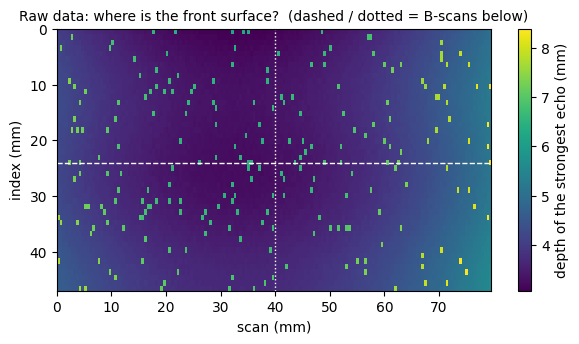

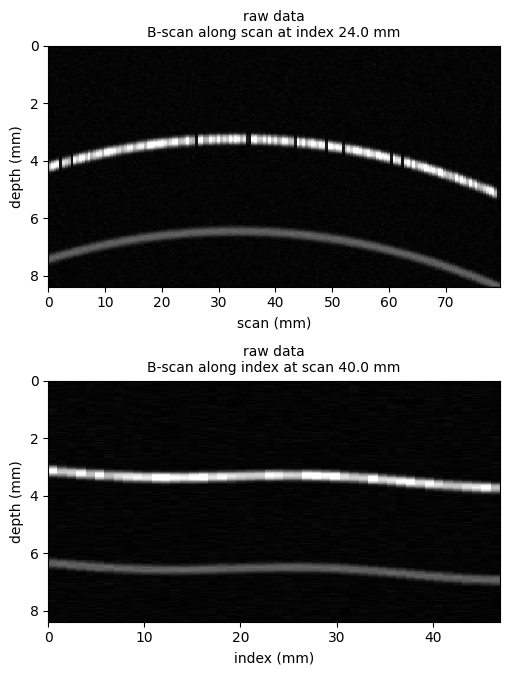

In [4]:
def envelope(data):
    # Amplitude envelope of the A-scans (always positive; easier to look at than the oscillating RF)
    return P.detection_signal(data, 'envelope')


def show_bscans(volumes, titles, i=None, j=None, depth=None, env=True, suptitle=''):
    # B-scans along scan (at index i) and along index (at scan j) for several volumes side by side
    v0 = volumes[0]
    i = v0.shape[0] // 2 if i is None else i
    j = v0.shape[1] // 2 if j is None else j
    fig, axes = plt.subplots(2, len(volumes), figsize=(5.2 * len(volumes), 7), squeeze=False)
    for c, (v, t) in enumerate(zip(volumes, titles)):
        img = envelope(v.data) if env else v.data
        lim = np.percentile(np.abs(img), 99.5)
        for r, (b, x, lab, where) in enumerate(((img[i], v.scan_mm, 'scan (mm)', f'index {v.index_mm[i]:.1f} mm'),
                                                (img[:, j], v.index_mm, 'index (mm)', f'scan {v.scan_mm[j]:.1f} mm'))):
            ax = axes[r, c]
            ax.imshow(b.T, aspect='auto', cmap='gray' if env else 'seismic', vmin=0 if env else -lim, vmax=lim,
                      extent=[x[0], x[-1], v.depth_mm[-1], v.depth_mm[0]])
            if depth is not None:
                ax.set_ylim(depth[1], depth[0])
            ax.set(title=f"{t}\nB-scan along {lab.split()[0]} at {where}", xlabel=lab, ylabel='depth (mm)')
    fig.suptitle(suptitle)
    fig.tight_layout()
    plt.show()


def strongest_echo_depth(v):
    return v.depth_mm[envelope(v.data).argmax(axis=2)]


I0, J0 = vol.shape[0] // 2, vol.shape[1] // 2            # B-scan positions used below (change them if you like)
surf = strongest_echo_depth(vol)
fig, ax = plt.subplots(figsize=(7, 3.4))
im = ax.imshow(surf, aspect='auto', cmap='viridis', extent=[vol.scan_mm[0], vol.scan_mm[-1], vol.index_mm[-1], vol.index_mm[0]])
ax.axhline(vol.index_mm[I0], color='w', ls='--', lw=1)
ax.axvline(vol.scan_mm[J0], color='w', ls=':', lw=1)
fig.colorbar(im, label='depth of the strongest echo (mm)')
ax.set(title='Raw data: where is the front surface?  (dashed / dotted = B-scans below)', xlabel='scan (mm)', ylabel='index (mm)')
plt.show()
show_bscans([vol], ['raw data'], I0, J0)

## 3. How the alignment works (the idea)

For **every A-scan separately**:

1. **Find the entrance echo**: the moment the signal first becomes strong enough inside a depth window
   where we expect the front surface (the *gate*).
2. **Fill the gaps**: where no echo was found (lost contact, a hole, the edge of the part), estimate the
   position from the neighbouring A-scans.
3. **Make neighbours agree** (refinement): small detection mistakes are removed by comparing every A-scan
   with its neighbours, because a real surface does not jump from one A-scan to the next.
4. **Move the A-scan** up so that this echo lands at 0 mm. The move can be a fraction of a sample; it is
   done with the Fourier transform (FFT), which *moves* the signal without changing its values or its
   frequency content (section 7 checks this).

Because each A-scan is treated on its own, the result does not depend on the *shape* of the surface: a
tilt, a curve or a wave are all corrected the same way.

The next sections do these steps one by one and show what each of them does.

## 4. Step 1 — Find the entrance echo ✏️

The echo is searched on a smooth, positive version of the signal (the **detection signal**), not on the raw
oscillating RF:

* `'envelope'`: the *envelope* of the RF (the outline of the oscillation, computed with the Hilbert
  transform). It does not depend on whether the signal happens to be positive or negative at a given sample.
* `'envelope_ma'` (**default**): the envelope, additionally smoothed by a short moving average over
  `AVERAGE_SAMPLES` samples, which removes little noise spikes.
* `'abs'`: simply the absolute value of the signal (use it for data that are already rectified).

Then, inside the **gate** (`GATE_MM`, the depth range where the front surface can be), the echo is:

* `METHOD = 'first'` (**default**): the first sample that goes above the threshold — the *start* of the echo.
  This is the usual choice: it is not fooled by a stronger reflection just after the surface.
* `METHOD = 'maximum'`: the strongest sample in the gate.

`PRE_ECHO_MM` keeps a little of the signal before the echo in the result (0.5 mm by default), so the
entrance echo is not cut in half at 0 mm.

The **threshold** is given as a fraction of the typical echo height (`THRESHOLD_FRACTION = 0.3` = 30 % of
it), so it works whatever the units of your data are.

**For a curved part, the gate must contain the front surface everywhere**, also where the part is
closest to and farthest from the probe. The cell suggests a gate from the data (the range of the strongest
echoes, with a margin); check it in the histogram and the A-scan plot below.

gate: 2.22 .. 7.64 mm   (suggested from the data)
threshold: 30% of the typical echo = 26.75 (data units)


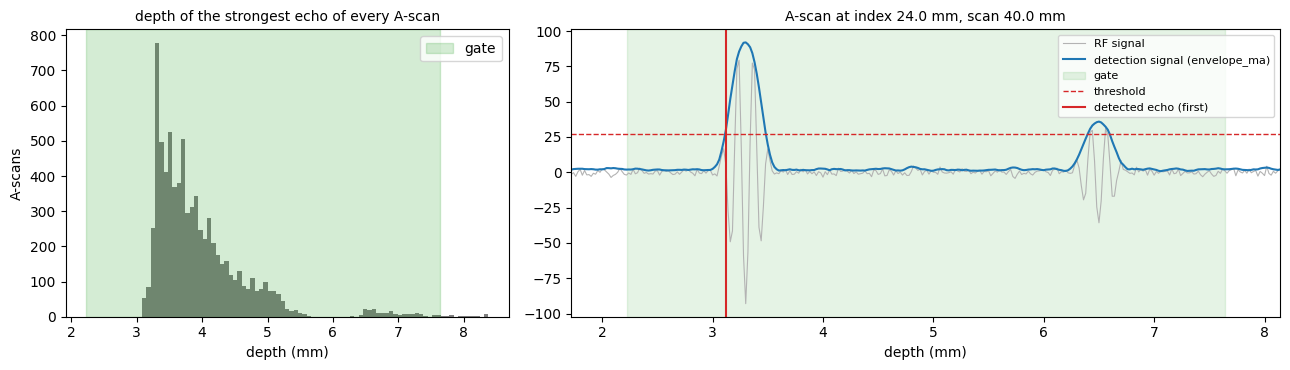

In [5]:
# ✏️ EDIT HERE ---------------------------------------------------------------------------------------
GATE_MM = None               # (start, end) in mm; None = suggested from the data (printed below)
THRESHOLD_FRACTION = 0.3     # fraction of the typical echo height
METHOD = 'first'             # 'first' or 'maximum'
SIGNAL = 'envelope_ma'       # 'envelope_ma', 'envelope' or 'abs'
AVERAGE_SAMPLES = 5          # moving average for 'envelope_ma'
PRE_ECHO_MM = 0.5            # keep this much signal before the echo (so the whole echo stays visible)
# ----------------------------------------------------------------------------------------------------

def suggest_gate(v, margin_mm=1.0):
    d = strongest_echo_depth(v)
    lo, hi = np.percentile(d, [2, 98])
    return (max(v.depth_mm[0], lo - margin_mm), min(v.depth_mm[-1], hi + margin_mm))


def absolute_threshold(v, gate, fraction, signal, average):
    # Threshold in the units of the data: fraction x the typical (median) peak height in the gate
    det = P.detection_signal(v.data, signal, average_samples=average)
    a, b = np.searchsorted(v.depth_mm, gate)
    return float(fraction * np.median(det[:, :, a:b].max(axis=2)))


gate = tuple(GATE_MM) if GATE_MM is not None else suggest_gate(vol)
threshold = absolute_threshold(vol, gate, THRESHOLD_FRACTION, SIGNAL, AVERAGE_SAMPLES)
print(f"gate: {gate[0]:.2f} .. {gate[1]:.2f} mm" + ("   (suggested from the data)" if GATE_MM is None else ''))
print(f"threshold: {THRESHOLD_FRACTION:.0%} of the typical echo = {threshold:.2f} (data units)")

# where are the strongest echoes, compared with the gate?
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), width_ratios=[1, 1.6])
a1.hist(surf.ravel(), bins=80, color='0.5')
a1.axvspan(*gate, color='tab:green', alpha=0.2, label='gate')
a1.set(title='depth of the strongest echo of every A-scan', xlabel='depth (mm)', ylabel='A-scans')
a1.legend()

# one A-scan: RF, detection signal, gate, threshold and the detected echo
det = P.detection_signal(vol.data[I0:I0 + 1, J0:J0 + 1], SIGNAL, average_samples=AVERAGE_SAMPLES)[0, 0]
rf = vol.data[I0, J0]
hit, sel = P.detect_echo_start_block(det[None, None], *np.searchsorted(vol.depth_mm, gate), threshold, 1.0, METHOD)
a2.plot(vol.depth_mm, rf, color='0.7', lw=0.8, label='RF signal')
a2.plot(vol.depth_mm, det, color='tab:blue', lw=1.5, label=f'detection signal ({SIGNAL})')
a2.axvspan(*gate, color='tab:green', alpha=0.12, label='gate')
a2.axhline(threshold, color='tab:red', ls='--', lw=1, label='threshold')
if hit[0, 0]:
    a2.axvline(vol.depth_mm[sel[0, 0]], color='tab:red', lw=1.5, label=f'detected echo ({METHOD})')
a2.set(title=f'A-scan at index {vol.index_mm[I0]:.1f} mm, scan {vol.scan_mm[J0]:.1f} mm', xlabel='depth (mm)')
a2.set_xlim(gate[0] - 0.5, gate[1] + 0.5)
a2.legend(fontsize=8, loc='upper right')
fig.tight_layout()
plt.show()

## 5. Step 2 — Fill the gaps

Some A-scans have no echo above the threshold inside the gate (for example where the probe lost contact,
over a hole, or outside the part). For those, the position is estimated from the closest A-scans that have
an echo (the 12 nearest ones, ignoring the ones that disagree strongly with the others).

The cell runs the detection and the gap filling, without the refinement of section 6, so you can see each
step on its own. The maps show which A-scans had an echo, and the depth of the echo everywhere.

7652 A-scans with an echo, 28 filled from their neighbours, 0 without a position   (0.0 s)


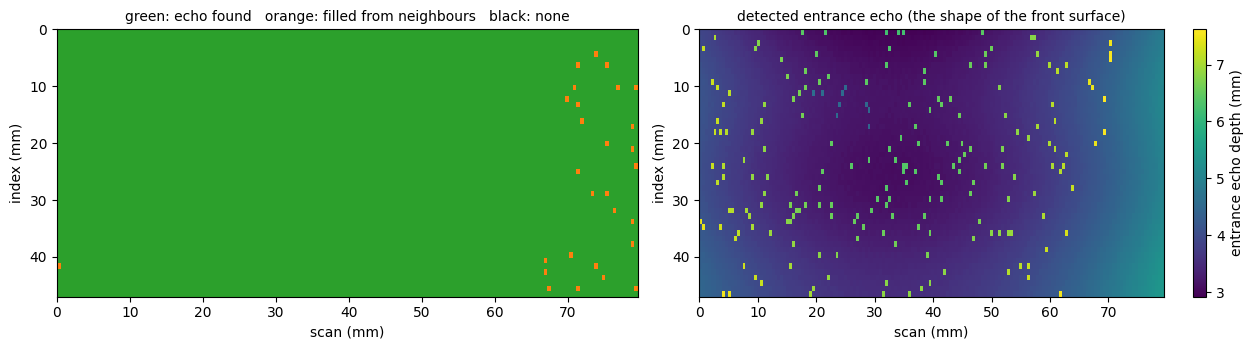

In [6]:
common = dict(gate_mm=gate, threshold_pct=threshold, method=METHOD, signal=SIGNAL, average_samples=AVERAGE_SAMPLES,
              interpolate_missing=True, neighbors=12, pre_echo_mm=PRE_ECHO_MM,
              resample='bandlimited')   # 'bandlimited' = the FFT move of section 7 (fractions of a sample)
t0 = time.time()
_, info_coarse, qc_coarse = P.echo_start(vol, **common, refine=None)
print(f"{info_coarse['hit_count']} A-scans with an echo, {info_coarse['interpolated_count']} filled from their "
      f"neighbours, {info_coarse['unresolved_count']} without a position   ({time.time() - t0:.1f} s)")

ext = [vol.scan_mm[0], vol.scan_mm[-1], vol.index_mm[-1], vol.index_mm[0]]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.6))
status = np.where(qc_coarse['hit'], 2, np.where(qc_coarse['interpolated'], 1, 0))
a1.imshow(status, aspect='auto', cmap=plt.matplotlib.colors.ListedColormap(['black', 'tab:orange', 'tab:green']),
          vmin=-0.5, vmax=2.5, extent=ext)
a1.set(title='green: echo found   orange: filled from neighbours   black: none', xlabel='scan (mm)', ylabel='index (mm)')
im = a2.imshow(qc_coarse['echo_mm'], aspect='auto', cmap='viridis', extent=ext)
fig.colorbar(im, ax=a2, label='entrance echo depth (mm)')
a2.set(title='detected entrance echo (the shape of the front surface)', xlabel='scan (mm)', ylabel='index (mm)')
fig.tight_layout()
plt.show()

## 6. Step 3 — Make neighbouring A-scans agree (refinement) ✏️

The detection of step 1 picks **one sample** per A-scan. When the echo has two peaks of similar height, or
the amplitude changes a bit, neighbouring A-scans can pick slightly different points of the same echo. In
the aligned B-scans this shows up as little **vertical steps** in the surface and in everything below it.

The refinement removes them in two stages:

1. **Clean-up**: every position is compared with the median of its neighbours (`MEDIAN_SIZE` x
   `MEDIAN_SIZE` A-scans). If it differs by more than `OUTLIER_SAMPLES` samples, it is a detection mistake
   and is replaced by that median. A real surface — flat, tilted or curved — changes smoothly at this scale,
   so this does not remove real shape.
2. **Waveform matching**: the shape of the echo of every A-scan (a short window around it, `WINDOW_MM`) is
   compared with the average echo of its neighbours, and the A-scan is moved by the small amount (at most
   `MAX_LAG_SAMPLES`, also fractions of a sample) that makes them match best (*cross-correlation*). A-scans
   whose echo does not look like its neighbours' (similarity below `MIN_CORRELATION`) are left as they were.
   Because the comparison is with the *local* neighbours, this also works where the surface is curved.

In the demo you will also see a few points far below the surface in the profile (grey dots): there the
echo was too weak, and the detection took the **back wall** instead. The clean-up recognises them as
mistakes and puts them back on the surface.

Set `REFINE = False` to see the result without it. `SMOOTH_SIGMA` (off by default) additionally smooths the
surface map; only use it if the surface really has no sharp features, because it would also smooth real
edges and steps.

done in 0.3 s
  clean-up replaced 299 positions; waveform matching moved 7675 A-scans (median similarity 0.997)
  neighbours differing by >= 2 samples:  along scan 30.0% -> 0.95%,  along index 25.87% -> 0.0%
  roughness of the aligned echo (lower = smoother): 4.91 -> 2.298


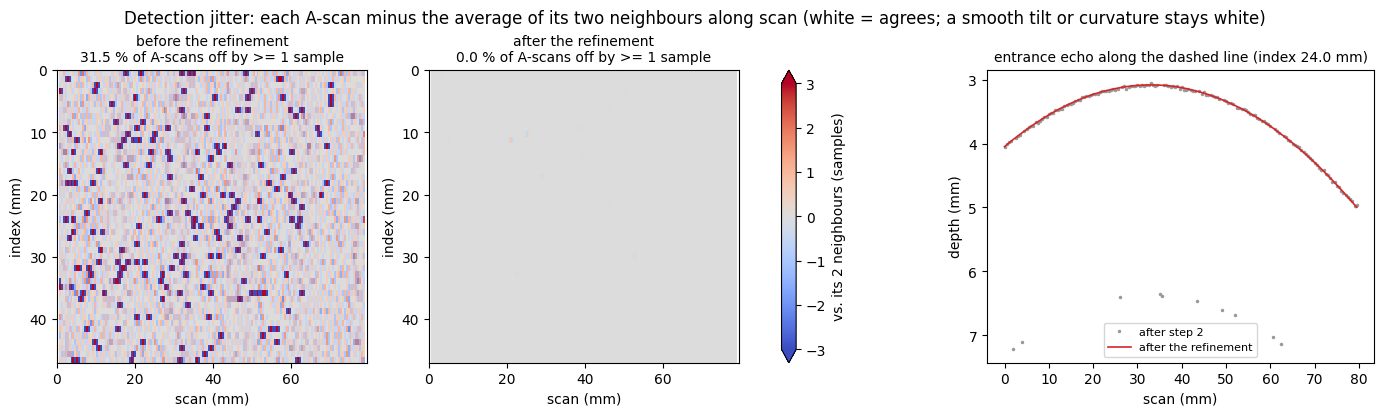

In [7]:
# ✏️ EDIT HERE ---------------------------------------------------------------------------------------
REFINE = True
MEDIAN_SIZE = 5              # neighbourhood for the clean-up (A-scans)
OUTLIER_SAMPLES = 1.5        # how far from the neighbours' median a position can be before it is a mistake
WINDOW_MM = (-0.5, 2.5)      # part of the A-scan compared with the neighbours (around the echo)
MAX_LAG_SAMPLES = 4          # largest correction (keep it below one oscillation of the signal)
MIN_CORRELATION = 0.5        # minimum similarity with the neighbours to apply the correction
SMOOTH_SIGMA = 0.0           # optional smoothing of the surface map (A-scans; 0 = off)
# ----------------------------------------------------------------------------------------------------

refine = dict(enabled=REFINE, median_size=MEDIAN_SIZE, outlier_samples=OUTLIER_SAMPLES, window_mm=list(WINDOW_MM),
              max_lag_samples=MAX_LAG_SAMPLES, min_correlation=MIN_CORRELATION, smooth_sigma_samples=SMOOTH_SIGMA)
t0 = time.time()
aligned, info, qc = P.echo_start(vol, **common, refine=refine)
print(f"done in {time.time() - t0:.1f} s")
r = info['refine']
if r['enabled']:
    b, a = r['before'], r['after']
    print(f"  clean-up replaced {r['outliers_cleaned']} positions; waveform matching moved {r['refined_by_correlation']} "
          f"A-scans (median similarity {r['median_correlation']})")
    print(f"  neighbours differing by >= 2 samples:  along scan {b['steps_2plus_scan_pct']}% -> {a['steps_2plus_scan_pct']}%,"
          f"  along index {b['steps_2plus_index_pct']}% -> {a['steps_2plus_index_pct']}%")
    print(f"  roughness of the aligned echo (lower = smoother): {b['roughness']} -> {a['roughness']}")

fig, axs = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, s, t in ((axs[0], qc['shift_coarse'], 'before the refinement'), (axs[1], qc['shift_samples'], 'after the refinement')):
    # each A-scan minus the average of its two neighbours along scan: 0 for any smooth surface (flat, tilted or curved)
    dev = np.full(s.shape, np.nan)
    dev[:, 1:-1] = s[:, 1:-1] - 0.5 * (s[:, :-2] + s[:, 2:])
    im = ax.imshow(dev, aspect='auto', cmap='coolwarm', vmin=-3, vmax=3, extent=ext)
    ax.set(title=f'{t}\n{np.nanmean(np.abs(dev) >= 1) * 100:.1f} % of A-scans off by >= 1 sample', xlabel='scan (mm)', ylabel='index (mm)')
fig.colorbar(im, ax=axs[:2], label='vs. its 2 neighbours (samples)', extend='both')
fig.suptitle('Detection jitter: each A-scan minus the average of its two neighbours along scan '
             '(white = agrees; a smooth tilt or curvature stays white)', y=1.04)
axs[2].plot(vol.scan_mm, vol.depth_mm[0] + qc['shift_coarse'][I0] * dk, '.', ms=3, color='0.6', label='after step 2')
axs[2].plot(vol.scan_mm, vol.depth_mm[0] + qc['shift_samples'][I0] * dk, '-', color='tab:red', lw=1.2, label='after the refinement')
axs[2].invert_yaxis()
axs[2].set(title=f'entrance echo along the dashed line (index {vol.index_mm[I0]:.1f} mm)', xlabel='scan (mm)', ylabel='depth (mm)')
axs[2].legend(fontsize=8)
plt.show()

## 7. Step 4 — Move the A-scans by fractions of a sample, with the FFT, and check the result

Each A-scan is now moved up by its own amount, so that its entrance echo is at 0 mm. The amounts are
usually **not whole samples** (e.g. 37.4 samples). Moving by a fraction of a sample by averaging neighbouring
samples (linear interpolation) would slightly smooth the signal and lower its peaks. Instead, the move is
done in the **frequency domain**: the A-scan is transformed with the FFT, a phase shift (the exact
mathematical equivalent of a time delay) is applied, and it is transformed back. This **moves the signal
without changing its frequency content** — the same frequencies with the same strengths, just later or
earlier. Whole-sample moves are a plain copy. Each A-scan is moved independently; nothing is mixed between
A-scans.

In more detail, for one A-scan moved by `s` samples (for example 37.4):

1. the A-scan is padded with zeros to twice its length (so that nothing "wraps around" from the end to the
   beginning, which the FFT would otherwise do);
2. it is transformed with the FFT into its frequencies;
3. every frequency `f` is multiplied by `exp(2πi·f·s)` — this changes only the *phase* of each frequency,
   never its strength, and is exactly a time shift by `s` samples, also when `s` is not a whole number;
4. it is transformed back, the padding is removed, and the samples that would come from beyond the end of
   the recording are set to 0.

If `s` is a whole number, the samples are simply copied (no FFT needed, and the result is identical).

The cell first shows the raw and aligned B-scans. Then it writes the FFT move out in a few lines (the
function `fft_shift`), so you can see that this is all that is done, and checks that it gives the same
result as the alignment code. Finally it compares it with the simple alternative, **linear interpolation**
(averaging the two neighbouring samples), using the same moves:

1. *one A-scan*: the dots are the raw samples at the position where they land after the move; the FFT
   curve passes through the true signal, interpolation cuts the peaks a little;
2. *round trip*: moving an A-scan and moving it back gives the original back with the FFT (error well
   below 1 %), while interpolation smooths it each time (error of the order of 20 % of the peak);
3. *energy*: the FFT keeps all the energy of the signal (100 %), interpolation loses part of it, because it
   averages away the fast oscillations;
4. *frequency content*: the FFT keeps it, interpolation loses the high frequencies.

(The *highest sample* of an A-scan can still change a little after an FFT move: the signal itself is the
same, but the samples now fall at slightly different points of it. That is why the energy is the fair
measure, not the highest sample.)

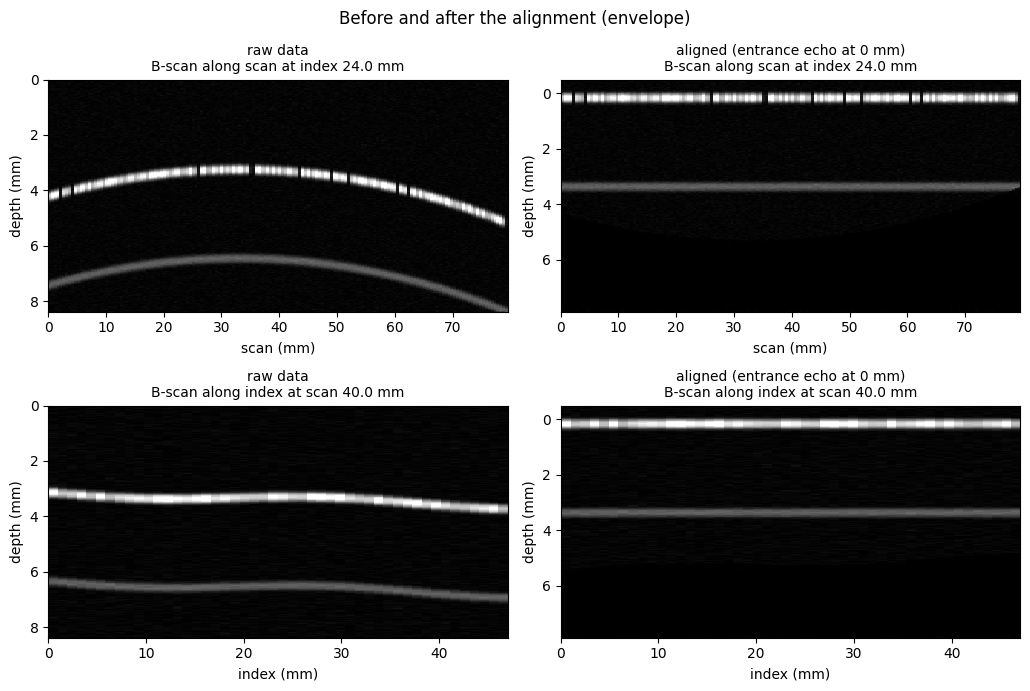

0 A-scans moved by whole samples (copied), 7680 by fractions of a sample (FFT)

A-scan at index 24.0 mm, scan 40.0 mm, moved by 156.380 samples:
  the 6 lines above give the same result as the alignment code: largest difference 6.9e-06 (float rounding)
  moved by 131.38 samples and moved back, largest error on the echo: FFT 0.12 %, linear interpolation 17.8 % of the peak
  (the small FFT error comes from the noise that was cut off at the edge of the recording; on a signal without noise it is ~0)


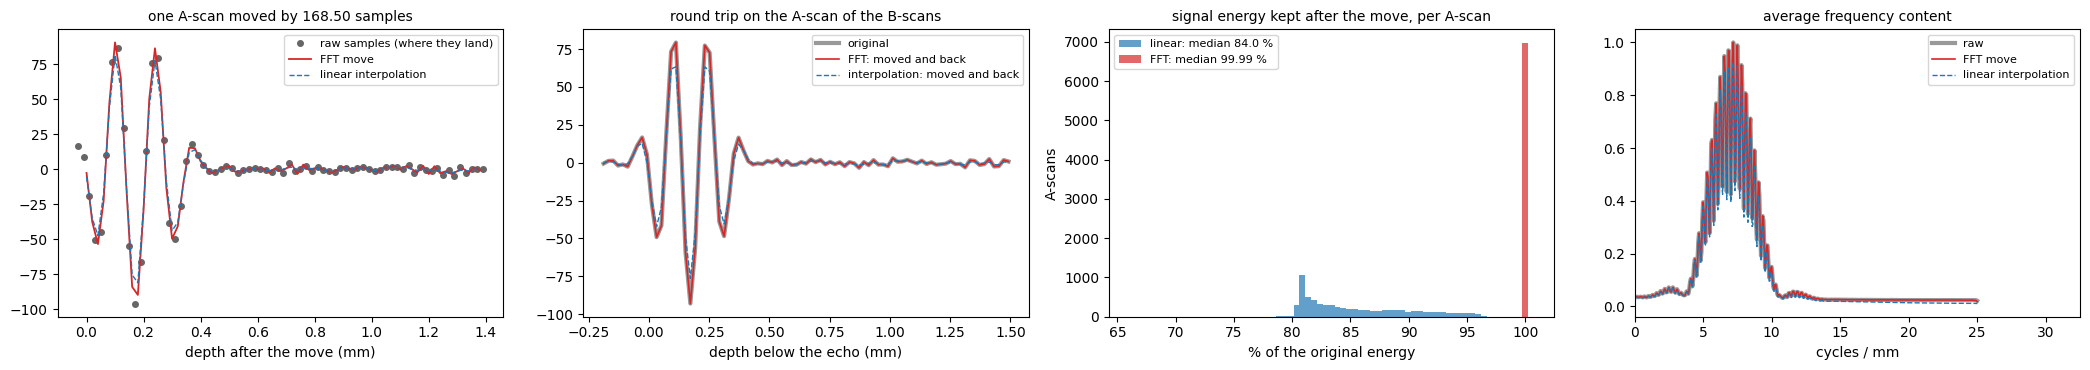

In [8]:
show_bscans([vol, aligned], ['raw data', 'aligned (entrance echo at 0 mm)'], I0, J0,
            suptitle='Before and after the alignment (envelope)')
print(f"{info['whole_sample_shifts']} A-scans moved by whole samples (copied), "
      f"{info['fractional_shifts']} by fractions of a sample (FFT)")


# --- The FFT move, written out: these few lines are all it does (steps 1-4 above) ---------------------
def fft_shift(a, s):
    # move the A-scan `a` earlier by `s` samples (s may be fractional; negative = later)
    n = a.size
    spectrum = np.fft.rfft(a, n=2 * n)                  # 1-2. pad with zeros to twice the length, FFT
    f = np.fft.rfftfreq(2 * n)                          #      the frequencies, in cycles per sample
    spectrum = spectrum * np.exp(2j * np.pi * f * s)    # 3.   phase ramp: only the phase changes
    b = np.fft.irfft(spectrum, n=2 * n)[:n]             # 4.   back, padding removed
    b[np.arange(n) >= n - s] = 0.0                      #      what would come from after the recording -> 0
    return b


shifts, applied = qc['shift_samples'], qc['applied']
raw = vol.data[I0, J0].astype(np.float64)
s = float(shifts[I0, J0])
mine = fft_shift(raw, s)
library = P.apply_shifts_bandlimited(vol.data[I0:I0 + 1, J0:J0 + 1], shifts[I0:I0 + 1, J0:J0 + 1],
                                     np.ones((1, 1), bool))[0, 0]
print(f"\nA-scan at index {vol.index_mm[I0]:.1f} mm, scan {vol.scan_mm[J0]:.1f} mm, moved by {s:.3f} samples:")
print(f"  the 6 lines above give the same result as the alignment code: largest difference "
      f"{np.abs(mine - library).max():.1e} (float rounding)")


# --- Round trip: move by s and back by -s. The FFT gives the original back; interpolation does not --------
def linear_shift(a, s):
    k = np.arange(a.size)
    return np.interp(k + s, k, a, right=0.0)


n = raw.size
s_used = s - qc['pre']                                    # the move the alignment applies (it keeps PRE_ECHO_MM before the echo)
kk = np.arange(n)
valid = (kk >= s - 0.2 / dk) & (kk <= s + 1.5 / dk)       # the entrance echo and what follows it
back_fft = fft_shift(fft_shift(raw, s_used), -s_used)
back_lin = linear_shift(linear_shift(raw, s_used), -s_used)
err = lambda b: 100 * np.abs(b - raw)[valid].max() / np.abs(raw).max()
print(f"  moved by {s_used:.2f} samples and moved back, largest error on the echo: FFT {err(back_fft):.2f} %, "
      f"linear interpolation {err(back_lin):.1f} % of the peak")
print("  (the small FFT error comes from the noise that was cut off at the edge of the recording; "
      "on a signal without noise it is ~0)")

# --- The whole volume: FFT move vs linear interpolation with the same shifts -------------------------------
lin = P.apply_echo_start_shifts(vol.data, shifts, applied)        # linear interpolation
fft = P.apply_shifts_bandlimited(vol.data, shifts, applied)       # FFT (what the alignment uses)
frac = applied & (np.abs(shifts - np.round(shifts)) > 0.05)        # A-scans moved by a real fraction
k = np.arange(vol.shape[2])
kept = k[None, None, :] >= np.ceil(shifts)[..., None]             # raw samples that are still in the recording
e_raw = (np.where(kept, vol.data, 0.0) ** 2).sum(-1)[frac]
e_lin = 100 * (lin ** 2).sum(-1)[frac] / e_raw
e_fft = 100 * (fft ** 2).sum(-1)[frac] / e_raw

fr = np.abs(shifts - np.round(shifts))
ii, jj = np.unravel_index(np.argmax(np.where(applied, -np.abs(fr - 0.5), -np.inf)), fr.shape)   # a move of x.5
s2 = float(shifts[ii, jj])
fig, axs = plt.subplots(1, 4, figsize=(21, 3.8))
zz = np.arange(vol.shape[2]) * dk
e0 = int(np.floor(s2))
sl = slice(0, 70)
zr = (k - s2) * dk                                                 # where every raw sample lands after the move
sr = (zr >= -0.05) & (zr < 70 * dk)
axs[0].plot(zr[sr], vol.data[ii, jj, sr], 'o', color='0.4', ms=4, label='raw samples (where they land)')
axs[0].plot(zz[sl], fft[ii, jj, sl], color='tab:red', lw=1.3, label='FFT move')
axs[0].plot(zz[sl], lin[ii, jj, sl], color='tab:blue', lw=1, ls='--', label='linear interpolation')
axs[0].set(title=f'one A-scan moved by {s2:.2f} samples', xlabel='depth after the move (mm)')
axs[0].legend(fontsize=8)
zk = (k - s) * dk
w = valid
axs[1].plot(zk[w], raw[w], color='0.6', lw=3, label='original')
axs[1].plot(zk[w], back_fft[w], color='tab:red', lw=1.2, label='FFT: moved and back')
axs[1].plot(zk[w], back_lin[w], color='tab:blue', lw=1, ls='--', label='interpolation: moved and back')
axs[1].set(title='round trip on the A-scan of the B-scans', xlabel='depth below the echo (mm)')
axs[1].legend(fontsize=8)
bins = np.linspace(min(e_lin.min(), 95), max(e_fft.max(), 100.5), 70)
axs[2].hist(e_lin, bins=bins, color='tab:blue', alpha=0.7, label=f'linear: median {np.median(e_lin):.1f} %')
axs[2].hist(e_fft, bins=bins, color='tab:red', alpha=0.7, label=f'FFT: median {np.median(e_fft):.2f} %')
axs[2].set(title='signal energy kept after the move, per A-scan', xlabel='% of the original energy', ylabel='A-scans')
axs[2].legend(fontsize=8)
n2 = 2 * vol.shape[2]
fq = np.fft.rfftfreq(n2, d=dk)
sp = lambda d: np.abs(np.fft.rfft(d[frac], n2, axis=-1)).mean(0)
s_raw, s_lin, s_fft = sp(np.where(kept, vol.data, 0.0)), sp(lin), sp(fft)
axs[3].plot(fq, s_raw / s_raw.max(), color='0.6', lw=3, label='raw')
axs[3].plot(fq, s_fft / s_raw.max(), color='tab:red', lw=1.2, label='FFT move')
axs[3].plot(fq, s_lin / s_raw.max(), color='tab:blue', lw=1, ls='--', label='linear interpolation')
axs[3].set_xlim(0, fq[np.flatnonzero(s_raw > 0.02 * s_raw.max())[-1]] * 1.3)
axs[3].set(title='average frequency content', xlabel='cycles / mm')
axs[3].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 8. Curved instead of only inclined front surfaces

A part that is only **tilted** has a front surface that is a straight, inclined line in every B-scan. Very
often, however, the surface in the raw data is **curved** (bent, bowl-shaped, wavy). Typical reasons:

* the part itself is curved or warped (thermal distortion of a composite panel, a curved component);
* the part is not lying flat: it rests on two points and sags, or it is clamped;
* the scanner or the probe holder does not move in a perfectly straight line, or the water path changes
  along the scan;
* a curved wedge, or the delay law of the array, adds a delay that changes across the aperture.

**What this means for the alignment.** A *tilt correction* (fitting a plane to the surface and removing it)
only removes the inclined part; the curvature stays in the data. The per-A-scan alignment of this notebook
removes **any** shape, because it measures the surface at every A-scan. The cell below:

1. fits a plane to the measured entrance echo and reports the **tilt** in both directions;
2. shows what is left after removing the plane: the **curvature** (and how large it is);
3. compares a *tilt-only* correction with the full alignment in the same B-scans.

**Things to keep in mind with curved parts**

* The gate (section 4) must contain the surface everywhere: with strong curvature the echo moves a lot in
  depth. A-scans where the echo falls outside the gate are filled from their neighbours (orange in section 5);
  if there are many of them, widen the gate.
* Keep `SMOOTH_SIGMA = 0`: the curvature is real and should not be smoothed away. The clean-up of the
  refinement only removes jumps between neighbouring A-scans, which is fine for smooth curves; if the
  surface is very strongly curved over a few A-scans (e.g. at a sharp radius), increase `OUTLIER_SAMPLES`
  so that real slopes are not taken for mistakes.
* The alignment corrects **timing** (where things appear in depth). On a strongly curved surface the sound
  also enters the part at an angle, which lowers the amplitude and bends the beam; the alignment does not
  change that. Depths below the surface are correct; amplitudes on steep parts of the curve may be lower.
* If the part is really curved, after the alignment the depth axis means *depth below the surface*, which is
  usually what you want for locating defects and plies.

tilt:      +0.68 deg along scan, +0.50 deg along index
curvature: the surface departs from that plane by up to 1.54 mm (peak to valley) = 77 samples  -> clearly curved, a tilt correction is not enough
           along scan: radius of curvature about 564 mm (centre closer to the probe than the ends)
           along index: radius of curvature about 1667 mm (centre closer to the probe than the ends)


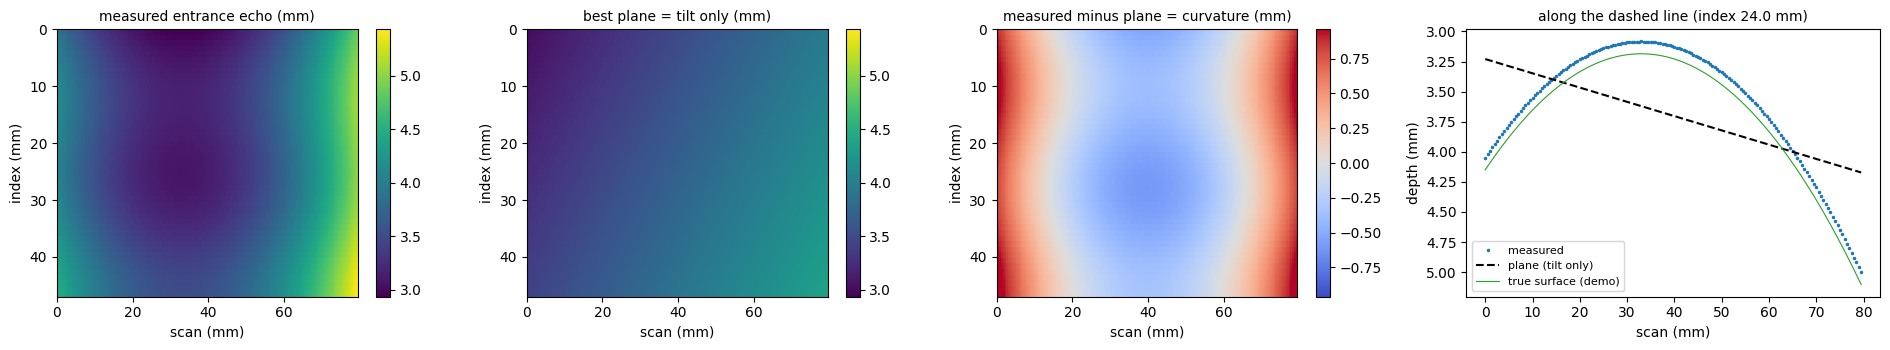

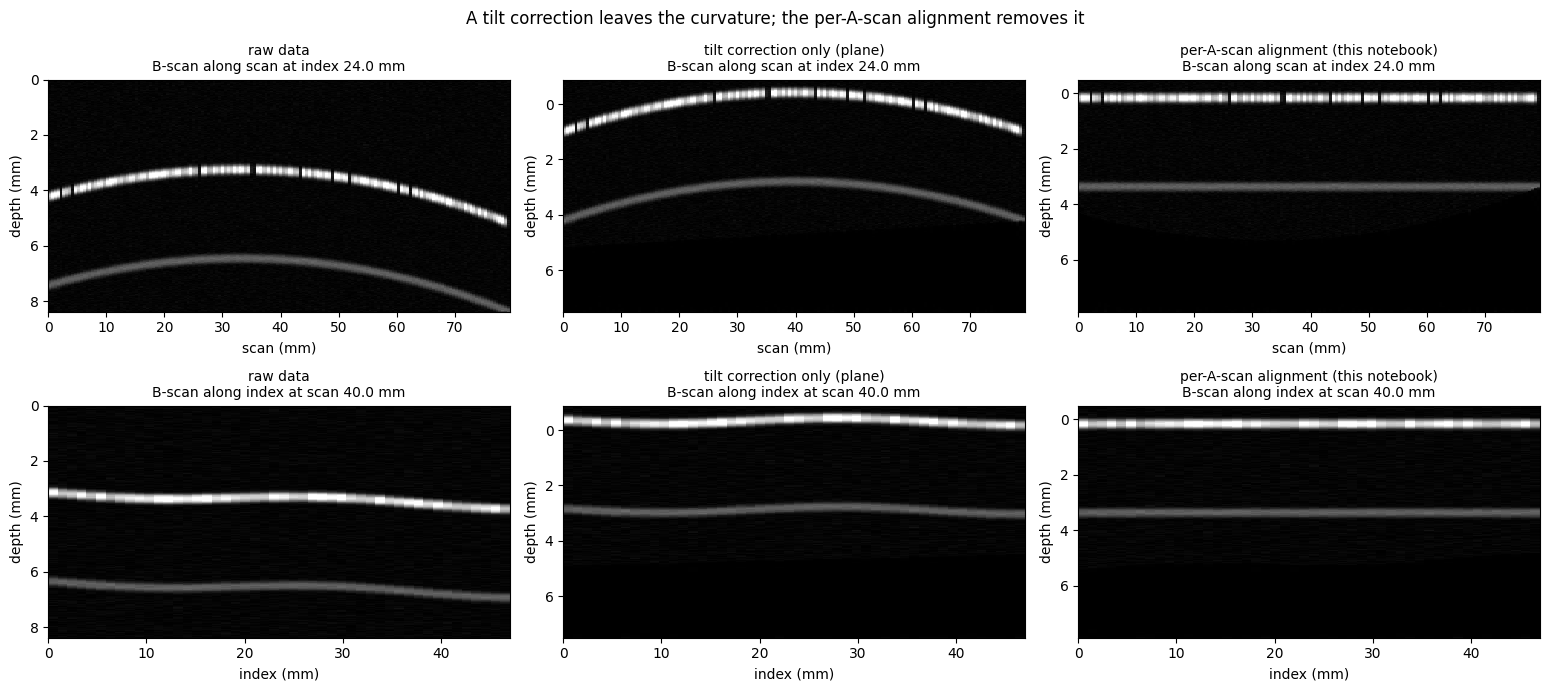

In [9]:
def plane_fit(echo_mm, v, mask):
    # least-squares plane  depth = a + b * index + c * scan  through the measured entrance echo
    I, J = np.meshgrid(v.index_mm, v.scan_mm, indexing='ij')
    A = np.column_stack([np.ones(mask.sum()), I[mask], J[mask]])
    coef, *_ = np.linalg.lstsq(A, echo_mm[mask], rcond=None)
    return coef[0] + coef[1] * I + coef[2] * J, coef


echo = qc['echo_mm']
ok = qc['hit']
plane, (a0, b_idx, c_scan) = plane_fit(echo, vol, ok)
resid = echo - plane
print(f"tilt:      {np.degrees(np.arctan(c_scan)):+.2f} deg along scan, {np.degrees(np.arctan(b_idx)):+.2f} deg along index")
pv = np.percentile(resid[ok], 99) - np.percentile(resid[ok], 1)
print(f"curvature: the surface departs from that plane by up to {pv:.2f} mm (peak to valley) "
      f"= {pv / dk:.0f} samples" + ("  -> clearly curved, a tilt correction is not enough" if pv > 5 * dk else "  -> essentially flat"))
# radius of curvature along each direction from a parabola through the middle line
for name, x, prof in (('scan', vol.scan_mm, resid[I0]), ('index', vol.index_mm, resid[:, J0])):
    m = np.isfinite(prof)
    if m.sum() > 5:
        k2 = np.polyfit(x[m], prof[m], 2)[0]
        print(f"           along {name}: radius of curvature about {abs(1 / (2 * k2)) if k2 else np.inf:.0f} mm "
              f"({'centre closer to the probe than the ends' if k2 > 0 else 'centre farther from the probe than the ends'})")

fig, axs = plt.subplots(1, 4, figsize=(19, 3.6), width_ratios=[1, 1, 1, 1.1])
for ax, img, t, cm in ((axs[0], echo, 'measured entrance echo (mm)', 'viridis'),
                       (axs[1], plane, 'best plane = tilt only (mm)', 'viridis'),
                       (axs[2], resid, 'measured minus plane = curvature (mm)', 'coolwarm')):
    lim = np.nanpercentile(np.abs(resid), 99) if cm == 'coolwarm' else None
    im = ax.imshow(img, aspect='auto', cmap=cm, extent=ext,
                   **({'vmin': -lim, 'vmax': lim} if lim else {'vmin': np.nanmin(echo), 'vmax': np.nanmax(echo)}))
    fig.colorbar(im, ax=ax)
    ax.set(title=t, xlabel='scan (mm)', ylabel='index (mm)')
axs[3].plot(vol.scan_mm, echo[I0], '.', ms=3, color='tab:blue', label='measured')
axs[3].plot(vol.scan_mm, plane[I0], '--', color='k', label='plane (tilt only)')
if vol.metadata.get('demo'):
    axs[3].plot(vol.scan_mm, vol.metadata['true_surface_mm'][I0], color='tab:green', lw=0.8, label='true surface (demo)')
axs[3].invert_yaxis()
axs[3].set(title=f'along the dashed line (index {vol.index_mm[I0]:.1f} mm)', xlabel='scan (mm)', ylabel='depth (mm)')
# (the measured line is slightly above the true surface: the echo is detected at its start, 'first' method)
axs[3].legend(fontsize=8)
fig.tight_layout()
plt.show()

# tilt-only correction: move every A-scan by the plane instead of by its own echo
margin = 0.3 - np.nanpercentile(resid[ok], 1)                     # so that the left-over curvature stays visible
tilt_shift = (plane - margin - vol.depth_mm[0]) / dk
tilt_only = P.replace(vol, data=P.apply_shifts_bandlimited(vol.data, tilt_shift, np.ones(tilt_shift.shape, bool)),
                      depth_mm=np.arange(vol.shape[2]) * dk - margin)
show_bscans([vol, tilt_only, aligned], ['raw data', 'tilt correction only (plane)', 'per-A-scan alignment (this notebook)'],
            I0, J0,
            suptitle='A tilt correction leaves the curvature; the per-A-scan alignment removes it')

## 9. C-scans: a map at one depth below the surface

A **C-scan** is a map of the signal at one depth (here: the strongest envelope in a thin slice). In the raw
data a slice at a fixed depth cuts diagonally through a tilted or curved part, so the map mixes the surface,
the inside of the part and the water. After the alignment, the same slice is at the **same depth below the
surface** everywhere, so features at that depth (defects, plies) appear as clean shapes.

Change `CSCAN_DEPTH_MM` (depth below the entrance echo, in the aligned data) to look at other depths.

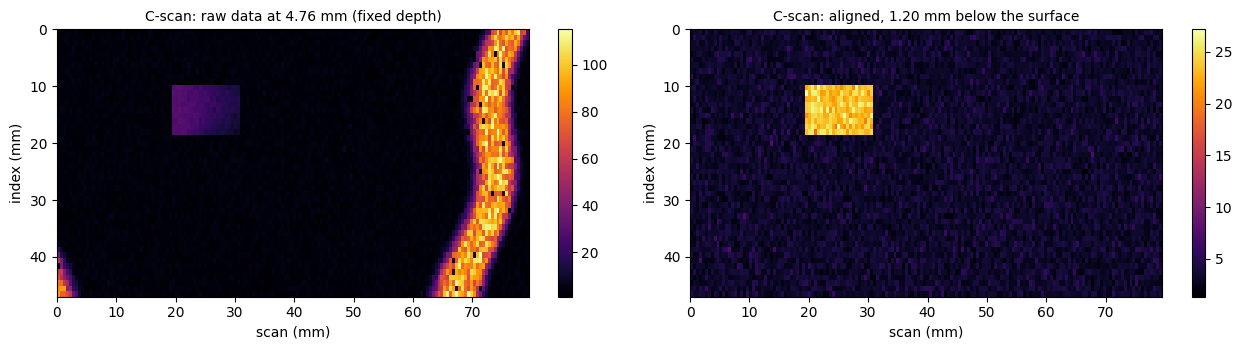

In [10]:
CSCAN_DEPTH_MM = 1.2     # ✏️ depth below the surface (mm)
CSCAN_THICKNESS_MM = 0.2

def cscan(v, z, half):
    a, b = np.searchsorted(v.depth_mm, [z - half, z + half])
    return envelope(v.data)[:, :, a:max(b, a + 1)].max(axis=2)

z_raw_equiv = float(np.nanmedian(echo)) + CSCAN_DEPTH_MM   # same depth in the raw data (at the median surface)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, img, t in ((a1, cscan(vol, z_raw_equiv, CSCAN_THICKNESS_MM / 2), f'raw data at {z_raw_equiv:.2f} mm (fixed depth)'),
                   (a2, cscan(aligned, CSCAN_DEPTH_MM, CSCAN_THICKNESS_MM / 2), f'aligned, {CSCAN_DEPTH_MM:.2f} mm below the surface')):
    im = ax.imshow(img, aspect='auto', cmap='inferno', extent=ext)
    fig.colorbar(im, ax=ax)
    ax.set(title=f'C-scan: {t}', xlabel='scan (mm)', ylabel='index (mm)')
fig.tight_layout()
plt.show()

## 10. Playground

Change the parameters with the controls and press **Run**: the alignment is recomputed and you see the
B-scans, the surface map and the quality numbers. Use it to find settings that work for your data, then
copy them into the cells of sections 4 and 6 if you want to keep them.

What to look for:

* the front surface should be a **straight line at 0 mm** in both B-scans;
* reflections inside the part (back wall, plies, defects) should be **continuous**, without little steps;
* in the status map, few or no **black** A-scans (no position) and not too many **orange** ones (filled).

If the controls do not appear, install `ipywidgets` (`pip install ipywidgets`) and restart the notebook.

In [11]:
try:
    import ipywidgets as W
    from IPython.display import display, clear_output
except ImportError:
    W = None
    print('ipywidgets is not installed: change the parameters in sections 4 and 6 instead')

if W is not None:
    g0 = gate
    st = {'description_width': '150px'}
    lay = W.Layout(width='420px')
    w = dict(
        gate=W.FloatRangeSlider(value=g0, min=float(vol.depth_mm[0]), max=float(vol.depth_mm[-1]), step=dk * 5,
                                description='gate (mm)', style=st, layout=lay, readout_format='.2f'),
        frac=W.FloatSlider(value=THRESHOLD_FRACTION, min=0.05, max=0.95, step=0.05, description='threshold (fraction)', style=st, layout=lay),
        method=W.Dropdown(options=['first', 'maximum'], value=METHOD, description='method', style=st, layout=lay),
        signal=W.Dropdown(options=['envelope_ma', 'envelope', 'abs'], value=SIGNAL, description='detection signal', style=st, layout=lay),
        avg=W.IntSlider(value=AVERAGE_SAMPLES, min=1, max=15, description='moving average', style=st, layout=lay),
        refine=W.Checkbox(value=REFINE, description='refinement', style=st),
        lag=W.IntSlider(value=MAX_LAG_SAMPLES, min=1, max=10, description='max correction (samples)', style=st, layout=lay),
        outl=W.FloatSlider(value=OUTLIER_SAMPLES, min=0.5, max=10, step=0.5, description='outlier limit (samples)', style=st, layout=lay),
        smooth=W.FloatSlider(value=SMOOTH_SIGMA, min=0, max=5, step=0.5, description='smoothing (A-scans)', style=st, layout=lay),
        i=W.IntSlider(value=I0, min=0, max=vol.shape[0] - 1, description='B-scan at index #', style=st, layout=lay),
        j=W.IntSlider(value=J0, min=0, max=vol.shape[1] - 1, description='B-scan at scan #', style=st, layout=lay),
    )
    run = W.Button(description='Run', button_style='primary', icon='play')
    out = W.Output()

    def on_run(_=None):
        with out:
            clear_output(wait=True)
            g = tuple(w['gate'].value)
            thr = absolute_threshold(vol, g, w['frac'].value, w['signal'].value, w['avg'].value)
            ref = dict(enabled=w['refine'].value, median_size=MEDIAN_SIZE, outlier_samples=w['outl'].value,
                       window_mm=list(WINDOW_MM), max_lag_samples=w['lag'].value, min_correlation=MIN_CORRELATION,
                       smooth_sigma_samples=w['smooth'].value)
            t0 = time.time()
            al, inf, q = P.echo_start(vol, gate_mm=g, threshold_pct=thr, method=w['method'].value, signal=w['signal'].value,
                                      average_samples=w['avg'].value, interpolate_missing=True, neighbors=12,
                                      pre_echo_mm=PRE_ECHO_MM, resample='bandlimited', refine=ref)
            msg = (f"{inf['hit_count']} echoes found, {inf['interpolated_count']} filled, {inf['unresolved_count']} without "
                   f"position  ({time.time() - t0:.1f} s)")
            if inf['refine']['enabled']:
                a_ = inf['refine']['after']
                msg += (f"\nsteps >= 2 samples after the refinement: {a_['steps_2plus_scan_pct']}% along scan, "
                        f"{a_['steps_2plus_index_pct']}% along index; roughness {a_['roughness']}")
            print(msg)
            fig, (x1, x2) = plt.subplots(1, 2, figsize=(13, 3.2))
            stt = np.where(q['hit'], 2, np.where(q['interpolated'], 1, 0))
            x1.imshow(stt, aspect='auto', cmap=plt.matplotlib.colors.ListedColormap(['black', 'tab:orange', 'tab:green']),
                      vmin=-0.5, vmax=2.5, extent=ext)
            x1.set(title='green: found  orange: filled  black: none', xlabel='scan (mm)', ylabel='index (mm)')
            im = x2.imshow(q['echo_mm'], aspect='auto', cmap='viridis', extent=ext)
            fig.colorbar(im, ax=x2, label='entrance echo (mm)')
            x2.set(title='front surface', xlabel='scan (mm)')
            plt.show()
            show_bscans([vol, al], ['raw data', 'aligned'], w['i'].value, w['j'].value)
            globals()['playground_result'] = (al, inf, q)

    run.on_click(on_run)
    display(W.HBox([W.VBox([w[k] for k in ('gate', 'frac', 'method', 'signal', 'avg', 'i')]),
                    W.VBox([w[k] for k in ('refine', 'lag', 'outl', 'smooth', 'j')] + [run])]), out)
    on_run()

Output()

## 11. Save the aligned volume ✏️

Writes the aligned data (the RF signal, not the envelope) and a small text file with every setting used,
so the result can be reproduced. The TIFF is stored as (depth, index, scan), the usual order for 3D image
viewers (Fiji/ImageJ, etc.), with the entrance echo at the depth given in the `.json` file.
To save the result of the playground instead, set `USE_PLAYGROUND = True`.

In [12]:
# ✏️ EDIT HERE ---------------------------------------------------------------------------------------
SAVE_TO = None               # e.g. r"C:\data\my_scan_aligned.tif"   (None = do not save)
USE_PLAYGROUND = False
# ----------------------------------------------------------------------------------------------------

if SAVE_TO:
    res_vol, res_info = (playground_result[0], playground_result[1]) if USE_PLAYGROUND else (aligned, info)
    out_path = Path(SAVE_TO)
    zyx = np.transpose(res_vol.data, (2, 0, 1)).astype(np.float32)
    if out_path.suffix.lower() in ('.tif', '.tiff'):
        import tifffile
        tifffile.imwrite(out_path, zyx, imagej=True, metadata={'axes': 'ZYX'})
    else:
        np.save(out_path.with_suffix('.npy'), zyx)
    record = {'source': str(FILE or 'demo'), 'axes_saved': ['depth', 'index', 'scan'],
              'spacing_mm': {'depth': dk, 'index': di, 'scan': dj},
              'depth_of_first_sample_mm': float(res_vol.depth_mm[0]), 'entrance_echo_at_mm': 0.0,
              'alignment': res_info}
    out_path.with_name(out_path.stem + '_alignment.json').write_text(json.dumps(record, indent=1, default=float))
    print('saved', out_path, 'and', out_path.stem + '_alignment.json')
else:
    print('set SAVE_TO to save the aligned volume')

set SAVE_TO to save the aligned volume


## 12. If something looks wrong

| What you see | What to try |
|---|---|
| The pictures in section 2 look rotated / the A-scans run sideways | Change `AXES` in section 1 |
| Many black or orange A-scans in the status map | The gate does not contain the echo there, or the threshold is too high: widen `GATE_MM`, lower `THRESHOLD_FRACTION` |
| The aligned surface is at 0 mm but noise or water reflections were taken as the echo | Threshold too low, or the gate starts too early: raise `THRESHOLD_FRACTION`, move the start of the gate closer to the surface |
| A strong reflection just below the surface is taken as the surface | Use `METHOD = 'first'` |
| Small steps remain in the aligned B-scans | Keep `REFINE = True`; try `MAX_LAG_SAMPLES` 5–6 and `MEDIAN_SIZE` 7 |
| A strongly curved region looks flattened wrongly / with jumps | Increase `OUTLIER_SAMPLES` (the clean-up thinks real slopes are mistakes) |
| Rectified data (only positive values) | `SIGNAL = 'abs'` |
| It is slow | The refinement takes most of the time; try it first on a part of the volume, e.g. `vol = P.replace(vol, data=vol.data[:, :200], scan_mm=vol.scan_mm[:200])` after section 1 |

**In short, what was done to the data:** every A-scan was moved in depth, by its own amount, so that its
entrance echo is at 0 mm. The values of the signal were not changed, only their position (the move by
fractions of a sample uses the FFT, which keeps the frequency content of the A-scan). A-scans are never
mixed with each other; the neighbours are only used to *decide* how much to move each one.